# IE313 — Phân tích giá Airbnb tại 10 thành phố châu Âu

**Notebook trình bày toàn bộ đồ án — Hàn (A) và Huy (B).**

Mục tiêu: mô tả phân phối giá, so sánh thành phố/loại phòng/hai nhóm ngày,
khảo sát liên hệ với các thuộc tính và so sánh năm mô hình hồi quy trên cùng giao thức.
Phân tích giúp giải thích vì sao chỉ nhìn giá trung bình hoặc một hệ số tương quan là chưa đủ,
và kiểm tra mức sai số của mô hình trên các quan sát được giữ riêng.

Phạm vi là 20 CSV đã có trong repo; không bổ sung dữ liệu, mô hình cây hay ứng dụng ngoài kế hoạch.
Nguồn dữ liệu được README ghi là Kaggle / The Devastator. `realSum` giữ nguyên thang giá:
EUR **theo README**, kỳ giá chưa xác minh metadata gốc; không diễn giải thành giá mỗi đêm.
AI hỗ trợ viết code và bản thảo; hai thành viên cần hiểu, kiểm tra và khai báo công cụ thực tế.

**Cách sử dụng:** mở file này và chọn **Restart Kernel and Run All**. Code kiểm dữ liệu,
chia tập, EDA, xây dựng Pipeline, CV, dự đoán và phần dư đều nằm trong notebook;
không cần chạy các notebook khác hoặc import `src`. Các notebook 01–06 giữ lại để truy vết quá trình.
Khi demo, dùng các output đã chạy; không dành thời gian thuyết trình cho việc huấn luyện lại.

Trình tự: 1. Nguồn và kiểm dữ liệu → 2. EDA/Pearson/ANOVA → 3. Giao thức và hồi quy
→ 4. Đánh giá holdout → 5. Phần dư và kết luận → 6. Phân công và cách kiểm tra.

## 1. Nguồn, từ điển và hiện trạng dữ liệu — Hàn, Huy kiểm tra

Nạp từng file để kiểm số mẫu/schema, rồi thêm `city`, `day_type`, `source_file`, `source_row`.
Khóa file/dòng giúp quay lại dữ liệu gốc; `Unnamed: 0` và tọa độ không phải listing ID.
CSV gộp phải khớp dữ liệu nạp lại trước khi sử dụng split đã chốt.

In [1]:
import hashlib
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import pearsonr, f_oneway
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Xác định thư mục gốc của dự án
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'config/experiment_config.json').is_file()
             and (p / 'data/raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Vui lòng mở notebook từ thư mục gốc của dự án hoặc thư mục notebooks.')

FINAL_DIR = ROOT / 'outputs/final_notebook'
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình hiển thị pandas và giao diện biểu đồ
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', font='DejaVu Sans')

print(f"Thư mục làm việc: {ROOT}")
print(f"Phiên bản Python: {sys.version.split()[0]}")



Thư mục làm việc: P:\CITD\HK3\Phân tích và trực quan dữ liệu\Đồ án môn học\Source
Phiên bản Python: 3.13.14


In [2]:
# 1. Nạp và kiểm tra tính nhất quán của 20 tệp dữ liệu thô
raw_csv_files = sorted((ROOT / 'data/raw').glob('*.csv'))
print(f"-> Tìm thấy {len(raw_csv_files)} tệp CSV thô trong thư mục data/raw.")

data_frames = []
inventory_records = []
original_columns = pd.read_csv(raw_csv_files[0], nrows=0).columns.tolist()

for file_path in raw_csv_files:
    df_part = pd.read_csv(file_path)
    if df_part.columns.tolist() != original_columns:
        raise ValueError(f"Tệp {file_path.name} có cấu trúc cột không khớp với chuẩn!")

    city_name, day_name = file_path.stem.rsplit('_', 1)
    inventory_records.append({
        'Tệp': file_path.name,
        'Thành phố': city_name,
        'Loại ngày': day_name,
        'Số dòng': len(df_part),
        'Số cột': len(df_part.columns),
        'Ô khuyết': int(df_part.isna().sum().sum())
    })

    # Bổ sung thông tin nguồn và khóa truy vết gốc
    df_part['city'] = city_name
    df_part['day_type'] = day_name
    df_part['source_file'] = file_path.name
    df_part['source_row'] = df_part['Unnamed: 0']
    data_frames.append(df_part)

# Hợp nhất dữ liệu
df = pd.concat(data_frames, ignore_index=True)
inventory = pd.DataFrame(inventory_records)

print(f"-> Đã hợp nhất thành công: {df.shape[0]:,} dòng x {df.shape[1]} cột.")
print(f"-> Số lượng thành phố: {df.city.nunique()} | Số nhóm (thành phố x loại ngày): {df.groupby(['city', 'day_type']).size().shape[0]}")
display(inventory)


-> Tìm thấy 20 tệp CSV thô trong thư mục data/raw.
-> Đã hợp nhất thành công: 51,707 dòng x 24 cột.
-> Số lượng thành phố: 10 | Số nhóm (thành phố x loại ngày): 20


,Tệp,Thành phố,Loại ngày,Số dòng,Số cột,Ô khuyết
0,amsterdam_weekdays.csv,amsterdam,weekdays,1103,20,0
1,amsterdam_weekends.csv,amsterdam,weekends,977,20,0
2,athens_weekdays.csv,athens,weekdays,2653,20,0
3,athens_weekends.csv,athens,weekends,2627,20,0
4,barcelona_weekdays.csv,barcelona,weekdays,1555,20,0
5,barcelona_weekends.csv,barcelona,weekends,1278,20,0
6,berlin_weekdays.csv,berlin,weekdays,1284,20,0
7,berlin_weekends.csv,berlin,weekends,1200,20,0
8,budapest_weekdays.csv,budapest,weekdays,2074,20,0
9,budapest_weekends.csv,budapest,weekends,1948,20,0


In [3]:
# 2. Xây dựng từ điển dữ liệu (Data Dictionary) chuẩn hóa cho 24 thuộc tính
dictionary_records = [
    {'column_name': 'Unnamed: 0', 'data_type': 'int64', 'category': 'Mã truy vết',
     'description_vi': 'Chỉ số dòng gốc trong từng tệp CSV (reset về 0 ở mỗi tệp)',
     'usage_note': 'Chỉ dùng làm khóa truy vết nội bộ; không phải ID listing toàn cục, không dùng làm biến dự báo.'},
    {'column_name': 'realSum', 'data_type': 'float64', 'category': 'Biến mục tiêu (Target)',
     'description_vi': 'Tổng giá thuê lưu trú (đơn vị EUR theo tài liệu mô tả dữ liệu)',
     'usage_note': 'Biến mục tiêu cần dự báo; giữ nguyên thang giá gốc, không biến đổi log khi huấn luyện mô hình.'},
    {'column_name': 'room_type', 'data_type': 'str', 'category': 'Biến phân loại (Categorical)',
     'description_vi': 'Loại phòng cho thuê trên Airbnb (Entire home/apt, Private room, Shared room)',
     'usage_note': 'Đặc trưng phân loại chính; được mã hóa One-Hot Encoding khi đưa vào mô hình hồi quy.'},
    {'column_name': 'room_shared', 'data_type': 'bool', 'category': 'Biến dư thừa',
     'description_vi': 'Cờ logic đánh dấu phòng chia sẻ (True nếu room_type là Shared room)',
     'usage_note': 'Trùng lặp với room_type. Loại bỏ khỏi tập biến dự báo để tránh đa cộng tuyến hoàn hảo.'},
    {'column_name': 'room_private', 'data_type': 'bool', 'category': 'Biến dư thừa',
     'description_vi': 'Cờ logic đánh dấu phòng riêng (True nếu room_type là Private room)',
     'usage_note': 'Trùng lặp với room_type. Loại bỏ khỏi tập biến dự báo để tránh đa cộng tuyến hoàn hảo.'},
    {'column_name': 'person_capacity', 'data_type': 'float64', 'category': 'Biến số (Predictor)',
     'description_vi': 'Sức chứa tối đa của chỗ nghỉ (số lượng khách từ 2 đến 6)',
     'usage_note': 'Đặc trưng số quan trọng; dùng cho mô hình đơn biến M1 và các mô hình đa biến.'},
    {'column_name': 'host_is_superhost', 'data_type': 'bool', 'category': 'Biến nhị phân (Predictor)',
     'description_vi': 'Chủ nhà đạt danh hiệu Superhost trên nền tảng Airbnb',
     'usage_note': 'Biến nhị phân logic; chuyển đổi sang dạng số 0/1 trong Pipeline.'},
    {'column_name': 'multi', 'data_type': 'int64', 'category': 'Biến phụ',
     'description_vi': 'Cờ nhị phân liên quan đến nhiều chỗ nghỉ của chủ nhà',
     'usage_note': 'Không đưa vào mô hình cốt lõi do thiếu định nghĩa chính thức trong tài liệu gốc.'},
    {'column_name': 'biz', 'data_type': 'int64', 'category': 'Biến phụ',
     'description_vi': 'Cờ nhị phân liên quan đến hoạt động kinh doanh chuyên nghiệp',
     'usage_note': 'Không đưa vào mô hình cốt lõi do thiếu định nghĩa chính thức trong tài liệu gốc.'},
    {'column_name': 'cleanliness_rating', 'data_type': 'float64', 'category': 'Biến số (Predictor)',
     'description_vi': 'Điểm đánh giá mức độ sạch sẽ của chỗ nghỉ (thang điểm quan sát 2 - 10)',
     'usage_note': 'Chuẩn hóa bằng StandardScaler trước khi đưa vào mô hình hồi quy đa biến.'},
    {'column_name': 'guest_satisfaction_overall', 'data_type': 'float64', 'category': 'Biến số (Predictor)',
     'description_vi': 'Điểm hài lòng tổng thể từ khách lưu trú (thang điểm quan sát 20 - 100)',
     'usage_note': 'Chuẩn hóa bằng StandardScaler trước khi đưa vào mô hình hồi quy đa biến.'},
    {'column_name': 'bedrooms', 'data_type': 'int64', 'category': 'Biến số (Predictor)',
     'description_vi': 'Số lượng phòng ngủ (từ 0 đến 10; giá trị 0 là phòng studio/phòng mở)',
     'usage_note': 'Đặc trưng số nguyên hợp lệ; chuẩn hóa bằng StandardScaler.'},
    {'column_name': 'dist', 'data_type': 'float64', 'category': 'Biến số (Predictor)',
     'description_vi': 'Khoảng cách từ chỗ nghỉ đến trung tâm thành phố (đơn vị km)',
     'usage_note': 'Đặc trưng vị trí địa lý cốt lõi; chuẩn hóa bằng StandardScaler.'},
    {'column_name': 'metro_dist', 'data_type': 'float64', 'category': 'Biến số (Predictor)',
     'description_vi': 'Khoảng cách từ chỗ nghỉ đến ga metro gần nhất (đơn vị km)',
     'usage_note': 'Đặc trưng vị trí địa lý; chuẩn hóa bằng StandardScaler.'},
    {'column_name': 'attr_index', 'data_type': 'float64', 'category': 'Chỉ số thô',
     'description_vi': 'Chỉ số sức hấp dẫn du lịch khu vực (giá trị thô)',
     'usage_note': 'Chỉ dùng cho mục đích khám phá mô tả; không đưa vào mô hình cốt lõi.'},
    {'column_name': 'attr_index_norm', 'data_type': 'float64', 'category': 'Chỉ số chuẩn hóa',
     'description_vi': 'Chỉ số sức hấp dẫn du lịch đã chuẩn hóa thang 100',
     'usage_note': 'Chỉ dùng cho mục đích khám phá mô tả; không đưa vào mô hình cốt lõi.'},
    {'column_name': 'rest_index', 'data_type': 'float64', 'category': 'Chỉ số thô',
     'description_vi': 'Chỉ số nhà hàng/ẩm thực khu vực (giá trị thô)',
     'usage_note': 'Chỉ dùng cho mục đích khám phá mô tả; không đưa vào mô hình cốt lõi.'},
    {'column_name': 'rest_index_norm', 'data_type': 'float64', 'category': 'Chỉ số chuẩn hóa',
     'description_vi': 'Chỉ số nhà hàng/ẩm thực đã chuẩn hóa thang 100',
     'usage_note': 'Chỉ dùng cho mục đích khám phá mô tả; không đưa vào mô hình cốt lõi.'},
    {'column_name': 'lng', 'data_type': 'float64', 'category': 'Tọa độ địa lý',
     'description_vi': 'Kinh độ địa lý của chỗ nghỉ',
     'usage_note': 'Dùng cho trực quan hóa bản đồ theo từng thành phố; không làm biến hồi quy tuyến tính toàn cục.'},
    {'column_name': 'lat', 'data_type': 'float64', 'category': 'Tọa độ địa lý',
     'description_vi': 'Vĩ độ địa lý của chỗ nghỉ',
     'usage_note': 'Dùng cho trực quan hóa bản đồ theo từng thành phố; không làm biến hồi quy tuyến tính toàn cục.'},
    {'column_name': 'city', 'data_type': 'str', 'category': 'Biến phân loại (Predictor)',
     'description_vi': 'Tên thành phố tại châu Âu (10 thành phố)',
     'usage_note': 'Biến phân nhóm quan trọng; mã hóa One-Hot Encoding trong Pipeline.'},
    {'column_name': 'day_type', 'data_type': 'str', 'category': 'Biến phân loại (Predictor)',
     'description_vi': 'Loại ngày khảo sát (weekdays - ngày thường hoặc weekends - cuối tuần)',
     'usage_note': 'Mã hóa One-Hot Encoding đại diện cho yếu tố thời điểm khảo sát.'},
    {'column_name': 'source_file', 'data_type': 'str', 'category': 'Mã truy vết',
     'description_vi': 'Tên tệp CSV nguồn gốc chứa bản ghi',
     'usage_note': 'Dùng đối chiếu và truy vết sai số; không dùng làm biến dự báo.'},
    {'column_name': 'source_row', 'data_type': 'int64', 'category': 'Mã truy vết',
     'description_vi': 'Chỉ số dòng gốc trong tệp CSV nguồn',
     'usage_note': 'Dùng đối chiếu và truy vết sai số; không dùng làm biến dự báo.'}
]

dictionary = pd.DataFrame(dictionary_records)
display(dictionary[['column_name', 'data_type', 'category', 'description_vi', 'usage_note']])


,column_name,data_type,category,description_vi,usage_note
0,Unnamed: 0,int64,Mã truy vết,Chỉ số dòng gốc trong từng tệp CSV (reset về 0...,Chỉ dùng làm khóa truy vết nội bộ; không phải ...
1,realSum,float64,Biến mục tiêu (Target),Tổng giá thuê lưu trú (đơn vị EUR theo tài liệ...,Biến mục tiêu cần dự báo; giữ nguyên thang giá...
2,room_type,str,Biến phân loại (Categorical),Loại phòng cho thuê trên Airbnb (Entire home/a...,Đặc trưng phân loại chính; được mã hóa One-Hot...
3,room_shared,bool,Biến dư thừa,Cờ logic đánh dấu phòng chia sẻ (True nếu room...,Trùng lặp với room_type. Loại bỏ khỏi tập biến...
4,room_private,bool,Biến dư thừa,Cờ logic đánh dấu phòng riêng (True nếu room_t...,Trùng lặp với room_type. Loại bỏ khỏi tập biến...
5,person_capacity,float64,Biến số (Predictor),Sức chứa tối đa của chỗ nghỉ (số lượng khách t...,Đặc trưng số quan trọng; dùng cho mô hình đơn ...
6,host_is_superhost,bool,Biến nhị phân (Predictor),Chủ nhà đạt danh hiệu Superhost trên nền tảng ...,Biến nhị phân logic; chuyển đổi sang dạng số 0...
7,multi,int64,Biến phụ,Cờ nhị phân liên quan đến nhiều chỗ nghỉ của c...,Không đưa vào mô hình cốt lõi do thiếu định ng...
8,biz,int64,Biến phụ,Cờ nhị phân liên quan đến hoạt động kinh doanh...,Không đưa vào mô hình cốt lõi do thiếu định ng...
9,cleanliness_rating,float64,Biến số (Predictor),Điểm đánh giá mức độ sạch sẽ của chỗ nghỉ (tha...,Chuẩn hóa bằng StandardScaler trước khi đưa và...


### 1.1. Kiểm toán chất lượng dữ liệu trước khi phân tích

Trong phân tích dữ liệu, việc tập dữ liệu không chứa ô trống (`NaN`) chưa đủ để khẳng định dữ liệu hoàn toàn hợp lệ. Nhóm thực hiện kiểm toán sâu trên các khía cạnh:
- **Tính hợp lý của giá trị số:** Giá thuê (`realSum`) phải là số dương ($> 0$), khoảng cách (`dist`, `metro_dist`) không được âm, tọa độ địa lý phải nằm trong phạm vi hợp lệ của châu Âu.
- **Tính toàn vẹn logic:** Các cờ logic loại phòng (`room_shared`, `room_private`) phải hoàn toàn nhất quán với giá trị của cột `room_type`.
- **Ký tự khuyết ẩn:** Kiểm tra các chuỗi đặc biệt thường dùng biểu diễn giá trị thiếu như `null`, `none`, `n/a`, `nan`, `?`.
- **Tính duy nhất của khóa truy vết:** Cặp (`source_file`, `source_row`) phải là duy nhất trên toàn bộ tập dữ liệu để đảm bảo khả năng truy xuất ngược.


In [4]:
def audit_data_quality(dataframe):
    """Kiểm tra toàn diện tính toàn vẹn và các quy tắc nghiệp vụ của dữ liệu."""
    hidden_null_count = sum(
        int(dataframe[col].astype(str).str.strip().str.lower().isin(
            ['', '?', '.', 'none', 'null', 'n/a', 'na', 'nan']).sum())
        for col in dataframe.select_dtypes(include=['object', 'str']).columns
    )

    rules = [
        ('1. Ô khuyết thiếu (Missing cells)', int(dataframe.isna().sum().sum())),
        ('2. Ký tự khuyết ẩn (null, none, n/a, ?)', hidden_null_count),
        ('3. Giá trị số không hữu hạn (NaN, Inf)', int((~np.isfinite(dataframe.select_dtypes(include='number'))).sum().sum())),
        ('4. Giá thuê không hợp lệ (realSum <= 0)', int((~dataframe.realSum.gt(0)).sum())),
        ('5. Trùng lặp khóa truy vết (source_file, source_row)', int(dataframe.duplicated(['source_file', 'source_row']).sum())),
        ('6. Loại phòng không thuộc danh mục hợp lệ', int((~dataframe.room_type.isin(['Entire home/apt', 'Private room', 'Shared room'])).sum())),
        ('7. Không khớp logic cờ room_shared', int((dataframe.room_shared != dataframe.room_type.eq('Shared room')).sum())),
        ('8. Không khớp logic cờ room_private', int((dataframe.room_private != dataframe.room_type.eq('Private room')).sum())),
        ('9. Cờ logic nhận giá trị ngoài True/False', sum(int((~dataframe[c].isin([True, False])).sum()) for c in ['room_shared', 'room_private', 'host_is_superhost'])),
        ('10. Sức chứa không hợp lệ (person_capacity < 1 hoặc không nguyên)', int((~(dataframe.person_capacity.ge(1) & dataframe.person_capacity.mod(1).eq(0))).sum())),
        ('11. Số phòng ngủ không hợp lệ (bedrooms < 0 hoặc không nguyên)', int((~(dataframe.bedrooms.ge(0) & dataframe.bedrooms.mod(1).eq(0))).sum())),
        ('12. Khoảng cách âm (dist hoặc metro_dist < 0)', int((dataframe[['dist', 'metro_dist']] < 0).sum().sum())),
        ('13. Tọa độ địa lý ngoài phạm vi châu Âu', int((~(dataframe.lat.between(-90, 90) & dataframe.lng.between(-180, 180))).sum()))
    ]

    report = pd.DataFrame(rules, columns=['Quy tắc kiểm tra', 'Số lượng vi phạm'])
    report['Đánh giá'] = np.where(report['Số lượng vi phạm'] == 0, 'Đạt', 'Không đạt')
    return report

quality_report = audit_data_quality(df)
display(quality_report)

print(f"-> Số dòng trùng lặp hoàn toàn 20 cột gốc: {df.duplicated(original_columns).sum()}")
print(f"-> Số bản ghi trùng tọa độ (city, lat, lng): {df.duplicated(['city', 'lat', 'lng']).sum():,} (đặc tính lấy mẫu trên cùng tòa nhà/khu vực)")
print(f"-> Khoảng cách metro nhỏ nhất ghi nhận: {df.metro_dist.min():.4f} km")
display(df.select_dtypes(include='number').describe().T)


,Quy tắc kiểm tra,Số lượng vi phạm,Đánh giá
0,1. Ô khuyết thiếu (Missing cells),0,Đạt
1,"2. Ký tự khuyết ẩn (null, none, n/a, ?)",0,Đạt
2,"3. Giá trị số không hữu hạn (NaN, Inf)",0,Đạt
3,4. Giá thuê không hợp lệ (realSum <= 0),0,Đạt
4,"5. Trùng lặp khóa truy vết (source_file, sourc...",0,Đạt
5,6. Loại phòng không thuộc danh mục hợp lệ,0,Đạt
6,7. Không khớp logic cờ room_shared,0,Đạt
7,8. Không khớp logic cờ room_private,0,Đạt
8,9. Cờ logic nhận giá trị ngoài True/False,0,Đạt
9,10. Sức chứa không hợp lệ (person_capacity < 1...,0,Đạt


-> Số dòng trùng lặp hoàn toàn 20 cột gốc: 0
-> Số bản ghi trùng tọa độ (city, lat, lng): 21,582 (đặc tính lấy mẫu trên cùng tòa nhà/khu vực)
-> Khoảng cách metro nhỏ nhất ghi nhận: 0.0023 km


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"51,707.0000","1,620.5024","1,217.3804",0.0000,646.0000,"1,334.0000","2,382.0000","5,378.0000"
realSum,"51,707.0000",279.8796,327.9484,34.7793,148.7522,211.3431,319.6943,"18,545.4503"
person_capacity,"51,707.0000",3.1617,1.2985,2.0000,2.0000,3.0000,4.0000,6.0000
multi,"51,707.0000",0.2914,0.4544,0.0000,0.0000,0.0000,1.0000,1.0000
biz,"51,707.0000",0.3502,0.4770,0.0000,0.0000,0.0000,1.0000,1.0000
cleanliness_rating,"51,707.0000",9.3906,0.9549,2.0000,9.0000,10.0000,10.0000,10.0000
guest_satisfaction_overall,"51,707.0000",92.6282,8.9455,20.0000,90.0000,95.0000,99.0000,100.0000
bedrooms,"51,707.0000",1.1588,0.6274,0.0000,1.0000,1.0000,1.0000,10.0000
dist,"51,707.0000",3.1913,2.3938,0.0150,1.4531,2.6135,4.2631,25.2846
metro_dist,"51,707.0000",0.6815,0.8580,0.0023,0.2485,0.4133,0.7378,14.2736


### 1.2. Phân tích phân phối giá và nhận diện điểm ngoại lai (IQR)

- **Đặc điểm phân phối:** Giá thuê (`realSum`) có phân phối lệch phải rất mạnh (hệ số bất đối xứng Skewness $> 20$). Giá trung bình (Mean $\approx 279,88$ EUR) bị kéo lệch đáng kể so với trung vị (Median $\approx 211,34$ EUR) bởi các bất động sản cao cấp có giá lên đến hàng nghìn EUR.
- **Phương pháp IQR:** Khoảng tứ phân vị $\text{IQR} = Q_3 - Q_1$ được sử dụng để xác định ranh giới giá thông thường: $[Q_1 - 1,5 \times \text{IQR},\ Q_3 + 1,5 \times \text{IQR}]$.
- **Quyết định phân tích:** Nhóm quyết định **giữ nguyên 100% các quan sát ngoại lai** trong quá trình phân tích và huấn luyện mô hình. Lý do: trong lĩnh vực lưu trú và du lịch, các căn hộ hạng sang có giá thuê cao là thực tế kinh doanh khách quan, không phải do lỗi nhập liệu. Việc loại bỏ nhân tạo sẽ làm sai lệch bản chất thị trường.


,Phạm vi,Số mẫu,Mean,Median,Std,Skewness,Max,Cận dưới IQR,Cận trên IQR,Số ngoại lai
0,Toàn bộ 10 thành phố,51707,279.8796,211.3431,327.9484,21.4200,"18,545.4503",-107.6610,576.1075,3662
1,amsterdam,2080,573.1128,460.2442,430.6584,6.4413,"8,130.6681",-200.0973,"1,218.3641",105
2,athens,5280,151.7441,127.7154,265.8801,62.8250,"18,545.4503",-10.6625,280.8567,293
3,barcelona,2833,293.7537,208.2994,355.4679,12.4221,"6,943.7010",-92.6292,583.2383,227
4,berlin,2484,244.5838,191.1751,235.3293,12.8469,"5,857.4834",-55.2725,478.5220,165
5,budapest,4022,176.5135,152.9821,131.1448,13.3766,"3,751.2337",15.6272,307.9616,223
6,lisbon,5763,238.2105,225.3752,108.9731,1.9415,"1,681.0507",-29.0807,475.6098,192
7,london,9993,362.4693,261.2950,471.3573,16.2823,"15,499.8942",-233.3075,841.0358,531
8,paris,6688,392.5314,317.5972,330.9497,19.4118,"16,445.6147",-90.7587,793.7599,386
9,rome,9027,205.3919,182.5918,118.6181,5.8493,"2,418.3480",-15.1965,394.4077,433


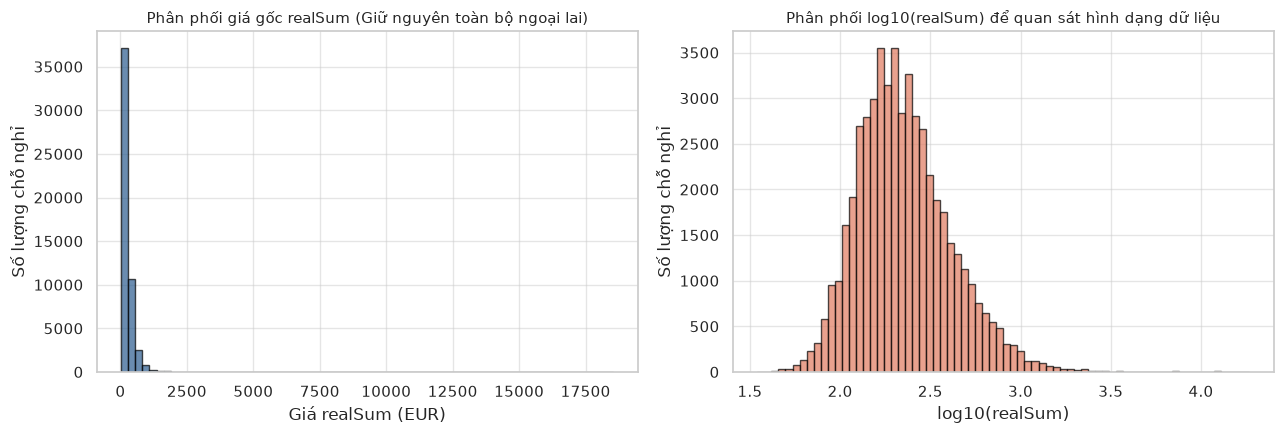

In [5]:
def calculate_price_iqr(frame):
    """Tính toán các chỉ số thống kê mô tả và ngưỡng IQR cho cột giá realSum."""
    price = frame.realSum
    q1 = price.quantile(0.25)
    q3 = price.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    return {
        'Số mẫu': len(frame),
        'Mean': price.mean(),
        'Median': price.median(),
        'Std': price.std(),
        'Skewness': price.skew(),
        'Max': price.max(),
        'Cận dưới IQR': lower_fence,
        'Cận trên IQR': upper_fence,
        'Số ngoại lai': int((price.lt(lower_fence) | price.gt(upper_fence)).sum())
    }

price_summary_rows = [{'Phạm vi': 'Toàn bộ 10 thành phố', **calculate_price_iqr(df)}]
for city_name, city_group in df.groupby('city'):
    price_summary_rows.append({'Phạm vi': city_name, **calculate_price_iqr(city_group)})

price_audit = pd.DataFrame(price_summary_rows)
display(price_audit)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df.realSum, bins=70, color='#2b5c8f', edgecolor='black', alpha=0.7)
axes[0].set_title('Phân phối giá gốc realSum (Giữ nguyên toàn bộ ngoại lai)', fontsize=11)
axes[0].set_xlabel('Giá realSum (EUR)')
axes[0].set_ylabel('Số lượng chỗ nghỉ')

axes[1].hist(np.log10(df.realSum), bins=70, color='#e07a5f', edgecolor='black', alpha=0.7)
axes[1].set_title('Phân phối log10(realSum) để quan sát hình dạng dữ liệu', fontsize=11)
axes[1].set_xlabel('log10(realSum)')
axes[1].set_ylabel('Số lượng chỗ nghỉ')

plt.tight_layout()
plt.show()


### 1.3. Phân nhóm mô tả khoảng cách và mức giá (Binning)

Để hỗ trợ phân tích cơ cấu và trực quan hóa phân bố, nhóm thực hiện phân nhóm hai thuộc tính liên tục:
- **Khoảng cách đến trung tâm (`dist_bin`):** Chia thành 4 khoảng: `[0, 1)` km, `[1, 3)` km, `[3, 5)` km và `[5, +inf)` km.
- **Phân khúc giá (`price_tier`):** Chia thành 4 phân khúc: `[0, 150)` EUR, `[150, 350)` EUR, `[350, 600)` EUR và `[600, +inf)` EUR.

*Lưu ý phương pháp luận:* Các thuộc tính phân nhóm này được tạo trên một bản sao riêng (`descriptive`) nhằm mục đích mô tả và lập bảng tần số chéo, **không đưa vào làm biến dự báo (predictor)** trong các mô hình học máy để tránh rò rỉ dữ liệu hoặc đa cộng tuyến.


In [6]:
descriptive = df.copy()

descriptive['dist_bin'] = pd.cut(
    descriptive.dist,
    bins=[0, 1, 3, 5, np.inf],
    labels=['[0, 1) km', '[1, 3) km', '[3, 5) km', '[5, +inf) km'],
    right=False
)

descriptive['price_tier'] = pd.cut(
    descriptive.realSum,
    bins=[0, 150, 350, 600, np.inf],
    labels=['[0, 150) EUR', '[150, 350) EUR', '[350, 600) EUR', '[600, +inf) EUR'],
    right=False
)

print("1. Thống kê giá theo các khoảng khoảng cách đến trung tâm:")
display(descriptive.groupby('dist_bin', observed=False).realSum.agg(
    n='size',
    mean='mean',
    median='median',
    std='std'
))

print("\n2. Bảng tần số chéo (Crosstab) giữa khoảng cách trung tâm và phân khúc giá:")
display(pd.crosstab(descriptive.dist_bin, descriptive.price_tier, margins=True, margins_name='Tổng'))


1. Thống kê giá theo các khoảng khoảng cách đến trung tâm:


,n,mean,median,std
dist_bin,,,,
"[0, 1) km",7279,297.2791,228.8931,317.1135
"[1, 3) km",21969,279.4675,210.1313,347.3614
"[3, 5) km",13421,292.0496,218.8296,330.3868
"[5, +inf) km",9038,248.7961,188.1440,278.4450



2. Bảng tần số chéo (Crosstab) giữa khoảng cách trung tâm và phân khúc giá:


price_tier,"[0, 150) EUR","[150, 350) EUR","[350, 600) EUR","[600, +inf) EUR",Tổng
dist_bin,,,,,
"[0, 1) km",1340,4355,1031,553,7279
"[1, 3) km",6005,11428,3074,1462,21969
"[3, 5) km",2930,7322,2202,967,13421
"[5, +inf) km",2946,4512,1237,343,9038
Tổng,13221,27617,7544,3325,51707


### 1.4. Tổng kết hiện trạng dữ liệu trước khi phân tích

- **Điểm mạnh:**
  - Quy mô mẫu lớn với 51.707 quan sát phủ khắp 10 thành phố lớn tại châu Âu.
  - Cấu trúc dữ liệu đồng nhất trên toàn bộ 20 tệp nguồn; không có giá trị khuyết thiếu trong tập dữ liệu cung cấp.
  - Đầy đủ cả 2 điều kiện khảo sát (ngày thường và cuối tuần) cho từng thành phố.
  - Đã thiết lập khóa truy vết (`source_file`, `source_row`) cho phép đối chiếu ngược lại từng dòng gốc khi kiểm tra sai số mô hình.

- **Thách thức và giới hạn:**
  - Phân phối giá lệch phải mạnh, tồn tại các căn hộ giá thuê rất cao. Do đó, cần luôn báo cáo song song cả Trung vị (Median) và IQR bên cạnh Trung bình (Mean).
  - Tỷ lệ các loại phòng chênh lệch lớn (Entire home/apt chiếm ~63%, Private room ~36%, trong khi Shared room chỉ chiếm 0.71%).
  - Tồn tại các trường hợp lặp tọa độ địa lý (các phòng khác nhau trong cùng một tòa nhà hoặc khu phức hợp).
  - Kết quả phân tích áp dụng cho tập dữ liệu khảo sát được cung cấp, không đại diện hoàn toàn cho toàn bộ thị trường lưu trú châu Âu tại mọi thời điểm.


## 2. EDA và bằng chứng liên hệ — Huy, Hàn kiểm tra

**Q1:** giá và số mẫu khác nhau thế nào theo city/room? **Q2:** hai nhóm ngày có khác nhau,
và chênh lệch có đi kèm khác cơ cấu phòng? **Q3:** liên hệ tuyến tính của thuộc tính với giá
gộp và trong từng city? **Q4:** mean giá khác nhau theo nhóm trong ANOVA, với giới hạn gì?

Trước EDA, đọc allowlist và khóa split đã chốt để tách bảng full/train. EDA không dùng để
tự động chọn biến theo r/p trên toàn bộ dữ liệu.

In [7]:
config = json.loads((ROOT / 'config/experiment_config.json').read_text(encoding='utf-8'))
manifest = pd.read_csv(ROOT / config['split']['manifest'])
hash_now = hashlib.sha256((ROOT / config['data_file']).read_bytes().replace(b'\r\n', b'\n')).hexdigest()
assert hash_now == config['data_sha256']
pd.testing.assert_frame_equal(df[config['trace_keys']], manifest[config['trace_keys']])
expected_train, expected_test = train_test_split(np.arange(len(df)), test_size=.2, random_state=0)
expected_train = np.sort(expected_train)
assert np.array_equal(np.flatnonzero(manifest.split.eq('train')), expected_train)
assert np.array_equal(np.flatnonzero(manifest.split.eq('test')), np.sort(expected_test))
assert manifest.loc[manifest.split.eq('test'), 'cv_fold'].eq(-1).all()
train = df.loc[manifest.split.eq('train')].reset_index(drop=True)
test = df.loc[manifest.split.eq('test')].reset_index(drop=True)
train_folds = manifest.loc[manifest.split.eq('train'), 'cv_fold'].to_numpy()
cv = [(np.flatnonzero(train_folds != fold), np.flatnonzero(train_folds == fold)) for fold in range(5)]
for fold, (fit_idx, valid_idx) in enumerate(KFold(5, shuffle=True, random_state=0).split(train)):
    assert np.array_equal(cv[fold][0], fit_idx) and np.array_equal(cv[fold][1], valid_idx)
assert len(train) == 41365 and len(test) == 10342
assert set(train_folds) == set(range(5))
display(pd.DataFrame([{'fold': f, 'fit': len(a), 'validation': len(b)} for f, (a,b) in enumerate(cv)]))

,fold,fit,validation
0,0,33092,8273
1,1,33092,8273
2,2,33092,8273
3,3,33092,8273
4,4,33092,8273


In [8]:
def predictor_names(config):
    p = config['predictors']
    return p['numeric'] + p['categorical'] + p['boolean']

In [9]:
# Các bảng của notebook cuối ghi riêng; không ghi đè sản phẩm bàn giao cũ.
LIMIT = ('Mô tả liên hệ, không nhân quả; giá lệch phải/nhóm mất cân đối, '
         'độc lập mẫu chưa xác minh do tọa độ lặp; p nhỏ không đo độ lớn tác động.')
def save_table(frame, name, root=ROOT):
    path = FINAL_DIR / name
    frame.to_csv(path, index=False, encoding='utf-8-sig')
    return path

def price_summary(df, columns):
    table = df.groupby(columns, observed=True)['realSum'].agg(
        n='size', mean='mean', median='median', std='std',
        q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)).reset_index()
    if len(columns) > 1:
        grid = pd.MultiIndex.from_product([sorted(df[c].unique()) for c in columns], names=columns)
        table = table.set_index(columns).reindex(grid).reset_index()
        table['n'] = table.n.fillna(0).astype(int)
    table['iqr'] = table.q3 - table.q1
    table['grouping'] = '+'.join(columns)
    table['availability'] = np.where(table.n.eq(0), 'no_observations', 'observed')
    return table


def build_eda_tables(df, root=ROOT):
    """Q1/Q2: bao gồm nhóm trống nhưng không gán giá 0 cho nhóm không có mẫu."""
    sets = [['city'], ['room_type'], ['city', 'day_type'], ['city', 'room_type'],
            ['city', 'room_type', 'day_type']]
    tables = [price_summary(df, cols) for cols in sets]
    summaries = pd.concat(tables, ignore_index=True)
    for _, g in summaries.groupby('grouping'):
        assert g.n.sum() == len(df)
        assert g.loc[g.n.eq(0), 'median'].isna().all()
    sampling = tables[-1].copy()
    sampling['share_of_city_day'] = sampling.n / sampling.groupby(['city', 'day_type']).n.transform('sum')
    pairs = sampling.pivot(index=['city', 'room_type'], columns='day_type', values=['n', 'mean', 'median'])
    pairs.columns = [metric + '_' + day for metric, day in pairs.columns]
    pairs = pairs.reset_index()
    pairs['median_difference_weekends_minus_weekdays'] = pairs.median_weekends - pairs.median_weekdays
    pairs['interpretation'] = 'Chênh hai nhóm quan sát; không ghép cặp cùng listing'
    # So sánh gộp city/day riêng, để thấy khác cơ cấu loại phòng.
    city_day = tables[2]
    city_pairs = city_day.pivot(index='city', columns='day_type', values=['n', 'mean', 'median'])
    city_pairs.columns = [metric + '_' + day for metric, day in city_pairs.columns]
    city_pairs = city_pairs.reset_index()
    city_pairs['median_difference_weekends_minus_weekdays'] = city_pairs.median_weekends - city_pairs.median_weekdays
    save_table(summaries, 'eda_group_summary.csv', root)
    save_table(sampling, 'eda_sampling_counts.csv', root)
    save_table(pairs, 'eda_day_comparison_by_room.csv', root)
    save_table(city_pairs, 'eda_day_comparison_by_city.csv', root)
    return summaries, sampling, city_pairs

In [10]:
group_summary, sampling, city_pairs = build_eda_tables(df)
display(group_summary.loc[group_summary.grouping.eq('city'), ['city', 'n', 'mean', 'median', 'iqr']])
display(group_summary.loc[group_summary.grouping.eq('room_type'), ['room_type', 'n', 'mean', 'median', 'iqr']])
display(city_pairs[['city', 'n_weekdays', 'n_weekends', 'median_weekdays', 'median_weekends',
                    'median_difference_weekends_minus_weekdays']])
display(pd.read_csv(FINAL_DIR / 'eda_day_comparison_by_room.csv'))

,city,n,mean,median,iqr
0,amsterdam,2080,573.1128,460.2442,354.6153
1,athens,5280,151.7441,127.7154,72.8798
2,barcelona,2833,293.7537,208.2994,168.9669
3,berlin,2484,244.5838,191.1751,133.4486
4,budapest,4022,176.5135,152.9821,73.0836
5,lisbon,5763,238.2105,225.3752,126.1726
6,london,9993,362.4693,261.2950,268.5858
7,paris,6688,392.5314,317.5972,221.1296
8,rome,9027,205.3919,182.5918,102.4010
9,vienna,3537,241.5825,208.4940,111.0254


,room_type,n,mean,median,iqr
10,Entire home/apt,32648,324.3152,248.4567,203.2275
11,Private room,18693,204.9402,166.3715,103.1782
12,Shared room,366,143.5662,124.4793,59.4382


,city,n_weekdays,n_weekends,median_weekdays,median_weekends,median_difference_weekends_minus_weekdays
0,amsterdam,"1,103.0000",977.0000,430.2486,491.6458,61.3971
1,athens,"2,653.0000","2,627.0000",127.7154,127.7154,0.0000
2,barcelona,"1,555.0000","1,278.0000",208.5321,204.6920,-3.8402
3,berlin,"1,284.0000","1,200.0000",187.7863,192.4605,4.6742
4,budapest,"2,074.0000","1,948.0000",147.4597,160.0320,12.5723
5,lisbon,"2,857.0000","2,906.0000",223.0300,227.7205,4.6904
6,london,"4,614.0000","5,379.0000",256.3560,268.1154,11.7594
7,paris,"3,130.0000","3,558.0000",318.5292,316.1991,-2.3301
8,rome,"4,492.0000","4,535.0000",179.7863,184.4622,4.6758
9,vienna,"1,738.0000","1,799.0000",204.5205,212.0001,7.4796


,city,room_type,n_weekdays,n_weekends,mean_weekdays,mean_weekends,median_weekdays,median_weekends,median_difference_weekends_minus_weekdays,interpretation
0,amsterdam,Entire home/apt,538.0000,588.0000,733.1791,736.0897,625.3369,614.4400,-10.8968,Chênh hai nhóm quan sát; không ghép cặp cùng l...
1,amsterdam,Private room,559.0000,385.0000,366.7647,407.7221,319.6401,350.3386,30.6986,Chênh hai nhóm quan sát; không ghép cặp cùng l...
2,amsterdam,Shared room,6.0000,4.0000,280.9739,280.7982,258.0086,229.7706,-28.2380,Chênh hai nhóm quan sát; không ghép cặp cùng l...
3,athens,Entire home/apt,"2,447.0000","2,425.0000",159.4463,150.6732,133.3396,133.3396,0.0000,Chênh hai nhóm quan sát; không ghép cặp cùng l...
4,athens,Private room,201.0000,196.0000,114.2659,111.3738,82.2534,78.1525,-4.1010,Chênh hai nhóm quan sát; không ghép cặp cùng l...
5,athens,Shared room,5.0000,6.0000,76.5355,80.3396,76.6293,83.4251,6.7959,Chênh hai nhóm quan sát; không ghép cặp cùng l...
6,barcelona,Entire home/apt,362.0000,180.0000,572.5601,745.0834,474.4339,532.0362,57.6023,Chênh hai nhóm quan sát; không ghép cặp cùng l...
7,barcelona,Private room,"1,185.0000","1,094.0000",202.7544,227.6689,185.2585,191.4260,6.1675,Chênh hai nhóm quan sát; không ghép cặp cùng l...
8,barcelona,Shared room,8.0000,4.0000,114.7974,142.6094,111.0154,145.2277,34.2123,Chênh hai nhóm quan sát; không ghép cặp cùng l...
9,berlin,Entire home/apt,474.0000,408.0000,351.9950,376.2302,289.8009,307.3292,17.5283,Chênh hai nhóm quan sát; không ghép cặp cùng l...


### 2.1. Biểu đồ nhóm và cơ cấu mẫu

Đọc count trước khi so sánh giá. Shared room có ít quan sát; tổ hợp không có mẫu có n=0,
giá giữ NaN thay vì điền 0. Chênh weekdays/weekends là hai tập quan sát, không ghép cặp cùng phòng.
Phân nhóm theo loại phòng giúp kiểm tra cơ cấu, chưa đủ để kết luận tác động nhân quả của cuối tuần.

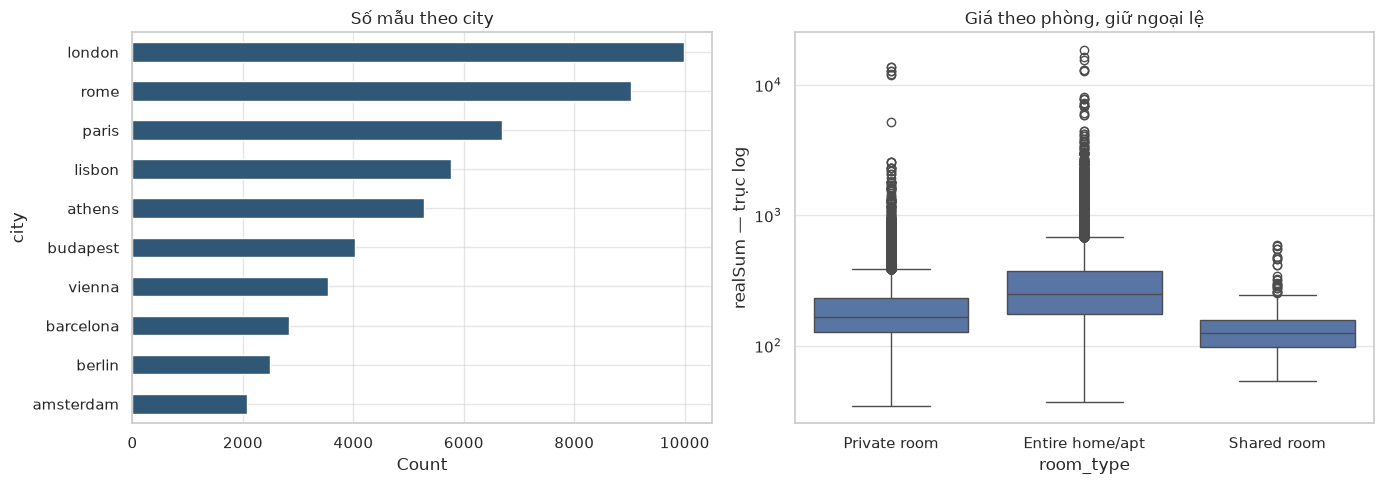

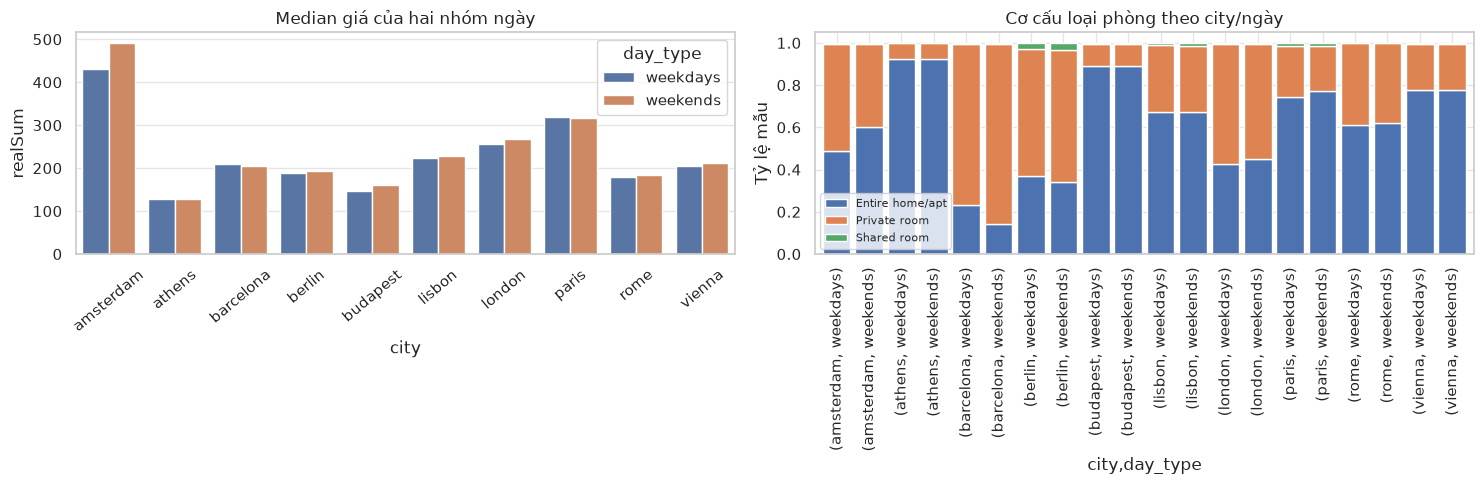

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
city_counts = df.city.value_counts().sort_values()
city_counts.plot.barh(ax=axes[0], color='#315776')
axes[0].set(title='Số mẫu theo city', xlabel='Count')
sns.boxplot(data=df, x='room_type', y='realSum', ax=axes[1], showfliers=True)
axes[1].set_yscale('log')
axes[1].set(title='Giá theo phòng, giữ ngoại lệ', ylabel='realSum — trục log')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
city_day = group_summary.loc[group_summary.grouping.eq('city+day_type')]
sns.barplot(data=city_day, x='city', y='median', hue='day_type', errorbar=None, ax=axes[0])
axes[0].tick_params(axis='x', rotation=40)
axes[0].set(title='Median giá của hai nhóm ngày', ylabel='realSum')
shares = sampling.pivot(index=['city', 'day_type'], columns='room_type', values='share_of_city_day')
shares.plot.bar(stacked=True, ax=axes[1], width=.85)
axes[1].set(title='Cơ cấu loại phòng theo city/ngày', ylabel='Tỷ lệ mẫu')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
def p_fields(p):
    """SciPy có thể underflow p thành 0; không diễn giải là xác suất bằng 0."""
    underflow = p == 0.0
    return {'p_value': np.nan if underflow else p,
            'p_display': 'underflow_float64; not exact zero' if underflow else f'{p:.4e}',
            'p_underflow': underflow, 'p_lt_0_05': bool(p < .05)}


def build_evidence(df, train, config, root=ROOT):
    numeric = ['person_capacity', 'bedrooms', 'dist', 'metro_dist', 'cleanliness_rating',
               'guest_satisfaction_overall', 'attr_index', 'attr_index_norm',
               'rest_index', 'rest_index_norm', 'lng', 'lat']
    allowed = set(predictor_names(config))
    pearson_rows, anova_rows, group_rows = [], [], []
    for scope, data in [('full_descriptive', df), ('train_descriptive', train)]:
        # Bảng train chỉ là diễn giải kiểm tra; allowlist không được lọc bằng r/p này.
        contexts = [('all_cities', data)] + list(data.groupby('city', sort=True))
        for context, group in contexts:
            for feature in numeric:
                x, y = group[feature], group.realSum
                valid = x.notna() & y.notna()
                if valid.sum() < 3 or x[valid].nunique() < 2:
                    r, p = np.nan, np.nan
                else:
                    r, p = pearsonr(x[valid].to_numpy(), y[valid].to_numpy())
                row = {'scope': scope, 'context': context, 'feature': feature, 'n': int(valid.sum()),
                       'method': 'Pearson', 'r': r, 'abs_r_ge_0_3': bool(abs(r) >= .3),
                       'used_in_core_model': feature in allowed, 'limitations': LIMIT}
                row.update(p_fields(p)); pearson_rows.append(row)
        for feature, context, group in [('city', 'all_cities', data),
                                         ('room_type', 'all_cities', data)] + [
                                         ('room_type', city, g) for city, g in data.groupby('city')]:
            groups = [(label, g.realSum.to_numpy()) for label, g in group.groupby(feature, observed=True)]
            arrays = [a for _, a in groups]
            variances = [np.var(a, ddof=1) for a in arrays if len(a) > 1]
            if len(arrays) >= 2 and all(len(a) >= 2 for a in arrays):
                f, p = f_oneway(*arrays)
            else:
                f, p = np.nan, np.nan
            row = {'scope': scope, 'context': context, 'feature': feature, 'method': 'One-way ANOVA',
                   'n': len(group), 'n_groups': len(groups), 'min_group_n': min(map(len, arrays)),
                   'f': f, 'variance_ratio_max_min': max(variances)/min(variances) if variances and min(variances)>0 else np.nan,
                   'used_in_core_model': feature in allowed, 'limitations': LIMIT}
            row.update(p_fields(p)); anova_rows.append(row)
            for label, a in groups:
                group_rows.append({'scope': scope, 'context': context, 'feature': feature,
                                   'group': label, 'n': len(a), 'mean': np.mean(a), 'median': np.median(a),
                                   'std': np.std(a, ddof=1) if len(a)>1 else np.nan})
    pearson = pd.DataFrame(pearson_rows)
    anova = pd.DataFrame(anova_rows)
    evidence = pd.concat([pearson, anova], ignore_index=True)
    evidence['decision'] = np.where(evidence.used_in_core_model, 'semantic_core_candidate', 'descriptive_only_excluded_core')
    evidence['decision_basis'] = 'Allowlist định trước theo ý nghĩa/metadata; r/p/F là mô tả, không tự động chọn theo y'
    save_table(pearson, 'pearson_price_evidence.csv', root)
    save_table(anova, 'anova_price_evidence.csv', root)
    save_table(pd.DataFrame(group_rows), 'anova_group_details.csv', root)
    save_table(evidence, 'feature_evidence.csv', root)
    corr = df[numeric + ['realSum']].corr()
    save_table(corr.reset_index(names='feature'), 'eda_correlation_matrix.csv', root)
    return pearson, anova, corr

,feature,n,r,p_display,used_in_core_model
0,person_capacity,51707,0.2031,underflow_float64; not exact zero,True
1,bedrooms,51707,0.2217,underflow_float64; not exact zero,True
2,dist,51707,-0.0447,2.5631e-24,True
3,metro_dist,51707,-0.0610,7.3765e-44,True
4,cleanliness_rating,51707,-0.0061,1.6668e-01,True
5,guest_satisfaction_overall,51707,-0.0019,6.6778e-01,True
6,attr_index,51707,0.1782,underflow_float64; not exact zero,False
7,attr_index_norm,51707,0.2924,underflow_float64; not exact zero,False
8,rest_index,51707,0.1347,5.7638e-208,False
9,rest_index_norm,51707,0.1441,6.5072e-238,False


,context,n,r,p_display
0,all_cities,51707,0.2031,underflow_float64; not exact zero
12,amsterdam,2080,0.5276,2.0514e-149
24,athens,5280,0.0915,2.7682e-11
36,barcelona,2833,0.3747,4.0989e-95
48,berlin,2484,0.3123,2.5747e-57
60,budapest,4022,0.2350,1.3556e-51
72,lisbon,5763,0.5729,underflow_float64; not exact zero
84,london,9993,0.3524,3.9353e-290
96,paris,6688,0.3956,1.8522e-249
108,rome,9027,0.4039,underflow_float64; not exact zero


,feature,n,min_group_n,f,p_display,variance_ratio_max_min
0,city,51707,2080,605.7186,underflow_float64; not exact zero,18.7095
1,room_type,51707,366,846.1375,underflow_float64; not exact zero,19.6865


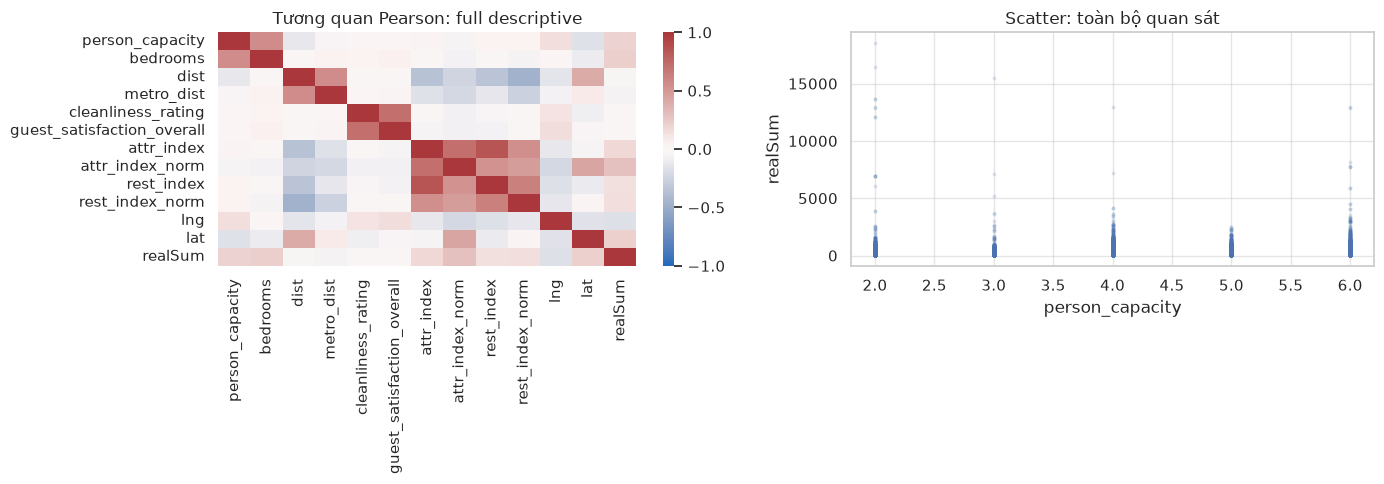

In [13]:
pearson, anova, corr = build_evidence(df, train, config)
display(pearson.loc[(pearson.scope == 'full_descriptive') & (pearson.context == 'all_cities'),
                    ['feature', 'n', 'r', 'p_display', 'used_in_core_model']])
display(pearson.loc[(pearson.scope == 'full_descriptive') & (pearson.feature == 'person_capacity'),
                    ['context', 'n', 'r', 'p_display']])
display(anova.loc[(anova.scope == 'full_descriptive') & (anova.context == 'all_cities'),
                  ['feature', 'n', 'min_group_n', 'f', 'p_display', 'variance_ratio_max_min']])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set(title='Tương quan Pearson: full descriptive')
axes[1].scatter(df.person_capacity, df.realSum, s=4, alpha=.12)
axes[1].set(xlabel='person_capacity', ylabel='realSum', title='Scatter: toàn bộ quan sát')
plt.tight_layout(); plt.show()

### 2.2. Diễn giải Pearson/ANOVA và vì sao không lọc biến máy móc

Pearson đo liên hệ tuyến tính, nhạy với giá lớn và việc gộp city; r gộp nhỏ không bác bỏ
liên hệ trong từng city. ANOVA kiểm khác biệt mean giữa nhóm, không chứng minh mọi cặp khác
nhau hay mức tác động lớn. Giá lệch, nhóm mất cân đối và tính độc lập chưa xác minh làm
giới hạn giả định kiểm định. p underflow được ghi rõ, không gọi xác suất chính xác bằng 0.

Giữ predictor theo ý nghĩa/metadata đã chốt; r/p/F là bằng chứng mô tả. Không áp ngưỡng
Pearson của bài tập giá xe để loại hết biến Airbnb. Tất cả bảng full/train được phân biệt.

## 3. Giao thức và năm mô hình hồi quy — Hàn M0–M2, Huy M3–M4

**41.365 train / 10.342 test**, seed 0, 5-fold CV trong train. Mỗi fold gồm 33.092 fit và
8.273 validation. So sánh cùng fold, target giá gốc và MSE CV trung bình.
Scaler/OneHot/Polynomial nằm trong Pipeline, được fit trong từng fold.

10 predictor gốc: sáu biến số, ba biến phân loại, một cờ Superhost. Không dùng ID,
log giá/price tier, cờ room trùng thông tin, metadata chưa chắc chắn hoặc tọa độ trong core.
`dist_bin` là dẫn xuất từ khoảng cách, được bỏ do dư thừa theo giao thức, không phải biến dẫn xuất từ target.

M0: trung bình train (mốc so sánh); M1: tuyến tính sức chứa; M2: tuyến tính đa biến;
M3: đa thức bậc 2/3 chỉ trên capacity/bedrooms/dist; M4: Ridge với bảy alpha đã định.
M2/M4 có 19 cột sau encoding; M3 bậc 2 có 25, bậc 3 có 35 cột. Chọn biến thể và mô hình
bằng CV trước phần đánh giá test. Test đã được mở ở T10 trước đây; lượt này tái lập giao thức
đã chốt, không giả vờ có một holdout mới chưa từng xem.

In [14]:
def build_pipeline(model_id, config, degree=None, alpha=None):
    """
    Xây dựng Pipeline khép kín cho từng mô hình hồi quy.
    Đảm bảo việc chuẩn hóa và mã hóa biến phân loại chỉ fit trên tập huấn luyện của từng fold.
    """
    numeric_features = config['predictors']['numeric']

    # M0: Mô hình Baseline trung bình (Mean Baseline)
    if model_id == 'M0':
        return Pipeline([('model', DummyRegressor(strategy='mean'))])

    # M1: Mô hình hồi quy đơn biến (SLR) với sức chứa
    if model_id == 'M1':
        preprocessor = ColumnTransformer(
            [('slr', 'passthrough', [config['slr_feature']])],
            remainder='drop'
        )
        return Pipeline([('preprocess', preprocessor), ('model', LinearRegression())])

    # Các bước tiền xử lý cho M2, M3, M4
    transformers = []

    # M3: Mở rộng đa thức cho các biến tương tác (person_capacity, bedrooms, dist)
    if model_id == 'M3':
        poly_features = config['polynomial_features']
        transformers.append(('polynomial', Pipeline([
            ('expand', PolynomialFeatures(degree=degree, include_bias=False)),
            ('scale', StandardScaler())
        ]), poly_features))
        numeric_features = [col for col in numeric_features if col not in poly_features]

    # Chuẩn hóa biến số và mã hóa One-Hot cho biến phân loại
    transformers += [
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False),
         config['predictors']['categorical']),
        ('boolean', 'passthrough', config['predictors']['boolean'])
    ]

    preprocessor = ColumnTransformer(transformers, remainder='drop')
    estimator = Ridge(alpha=alpha) if model_id == 'M4' else LinearRegression()

    return Pipeline([('preprocess', preprocessor), ('model', estimator)])


def evaluate_cv(pipeline, train_data, cv_folds, config, model_id, variant_name):
    """
    Đánh giá mô hình qua 5-Fold Cross Validation trên tập Train.
    Ghi nhận chi tiết kết quả từng fold và giá trị trung bình kèm độ lệch chuẩn.
    """
    X = train_data[predictor_names(config)]
    y = train_data[config['target']]

    cv_results = cross_validate(
        pipeline, X, y, cv=cv_folds,
        scoring={'mse': 'neg_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'},
        return_train_score=True, n_jobs=1, error_score='raise'
    )

    fold_records = []
    for fold_idx in range(len(cv_folds)):
        record = {
            'model_id': model_id,
            'variant': variant_name,
            'fold': fold_idx,
            'n_fold_train': len(cv_folds[fold_idx][0]),
            'n_fold_validation': len(cv_folds[fold_idx][1]),
            'protocol_id': config['protocol_id']
        }
        for split_key, prefix in [('test', 'validation'), ('train', 'train')]:
            record[f'{prefix}_mse'] = -cv_results[f'{split_key}_mse'][fold_idx]
            record[f'{prefix}_rmse'] = np.sqrt(record[f'{prefix}_mse'])
            record[f'{prefix}_mae'] = -cv_results[f'{split_key}_mae'][fold_idx]
            record[f'{prefix}_r2'] = cv_results[f'{split_key}_r2'][fold_idx]
        fold_records.append(record)

    df_folds = pd.DataFrame(fold_records)
    summary = {
        'model_id': model_id,
        'variant': variant_name,
        'protocol_id': config['protocol_id'],
        'n_train': len(train_data),
        'n_folds': len(cv_folds)
    }
    for split_key, prefix in [('validation', 'cv'), ('train', 'fold_train')]:
        for metric in ['mse', 'rmse', 'mae', 'r2']:
            summary[f'{prefix}_{metric}_mean'] = df_folds[f'{split_key}_{metric}'].mean()
            summary[f'{prefix}_{metric}_std'] = df_folds[f'{split_key}_{metric}'].std(ddof=1)

    return summary, df_folds


In [15]:
X_train, y_train = train[predictor_names(config)], train[config['target']]
specs = [('M0', 'mean_baseline', {}), ('M1', 'slr_person_capacity', {}), ('M2', 'mlr_core', {})]
specs += [('M3', f'degree_{d}', {'degree': d}) for d in config['polynomial_degrees']]
specs += [('M4', f'alpha_{a:g}', {'alpha': a}) for a in config['ridge_alphas']]
cv_rows, fold_rows = [], []
for model_id, variant, params in specs:
    pipeline = build_pipeline(model_id, config, **params)
    summary, detail = evaluate_cv(pipeline, train, cv, config, model_id, variant)
    cv_rows.append({**summary, **params})
    fold_rows.append(detail)
    print(model_id, variant, 'CV MSE =', round(summary['cv_mse_mean'], 2))
cv_summary = pd.DataFrame(cv_rows)
cv_folds = pd.concat(fold_rows, ignore_index=True)
assert len(cv_summary) == 12 and len(cv_folds) == 60
display(cv_summary[['model_id', 'variant', 'fold_train_mse_mean', 'cv_mse_mean',
                    'cv_mse_std', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean']])
save_table(cv_summary, 'all_configurations_cv.csv')
save_table(cv_folds, 'all_configurations_folds.csv')

M0 mean_baseline CV MSE = 104402.75
M1 slr_person_capacity CV MSE = 99919.96
M2 mlr_core CV MSE = 79988.15
M3 degree_2 CV MSE = 79616.75
M3 degree_3 CV MSE = 79228.0
M4 alpha_0.001 CV MSE = 79988.15
M4 alpha_0.01 CV MSE = 79988.15
M4 alpha_0.1 CV MSE = 79988.15
M4 alpha_1 CV MSE = 79988.33
M4 alpha_10 CV MSE = 80006.64
M4 alpha_100 CV MSE = 80725.81
M4 alpha_1000 CV MSE = 84147.42


,model_id,variant,fold_train_mse_mean,cv_mse_mean,cv_mse_std,cv_rmse_mean,cv_mae_mean,cv_r2_mean
0,M0,mean_baseline,"104,401.9283","104,402.7536","18,227.9902",322.0892,146.4071,-0.0000
1,M1,slr_person_capacity,"99,918.5690","99,919.9617","18,372.5085",314.9863,139.1291,0.0443
2,M2,mlr_core,"79,912.3698","79,988.1486","18,800.2106",281.1684,104.3512,0.2409
3,M3,degree_2,"79,455.2486","79,616.7538","18,821.2735",280.4955,103.2599,0.2446
4,M3,degree_3,"78,883.6584","79,227.9979","18,787.1387",279.8001,102.9403,0.2483
5,M4,alpha_0.001,"79,912.3698","79,988.1485","18,800.2109",281.1684,104.3512,0.2409
6,M4,alpha_0.01,"79,912.3698","79,988.1483","18,800.2133",281.1684,104.3509,0.2409
7,M4,alpha_0.1,"79,912.3719","79,988.1477","18,800.2368",281.1684,104.3486,0.2409
8,M4,alpha_1,"79,912.5822","79,988.3306","18,800.4737",281.1687,104.3256,0.2409
9,M4,alpha_10,"79,931.1348","80,006.6364","18,802.9823",281.2012,104.1329,0.2407


WindowsPath('P:/CITD/HK3/Phân tích và trực quan dữ liệu/Đồ án môn học/Source/outputs/final_notebook/all_configurations_folds.csv')

`cross_validate` gọi điểm validation là `test_*`; hàm đã đổi tên để không nhầm holdout.
MSE/MAE scorer có dấu âm được đổi về dương, R² giữ nguyên. Mean RMSE của folds không nhất
thiết bằng căn mean MSE. Chênh train/CV phản ánh sai số trong cấu hình này; chưa đủ để
tuyên bố chắc chắn mô hình không overfit.

In [16]:
selected_cv = cv_summary.loc[cv_summary.groupby('model_id').cv_mse_mean.idxmin()].copy()
winner_id = selected_cv.loc[selected_cv.cv_mse_mean.idxmin(), 'model_id']
selected_cv['selected_winning_model'] = selected_cv.model_id.eq(winner_id)
models = {}
for row in selected_cv.itertuples():
    params = {'degree': int(row.degree)} if row.model_id == 'M3' else (
             {'alpha': float(row.alpha)} if row.model_id == 'M4' else {})
    model = build_pipeline(row.model_id, config, **params)
    model.fit(X_train, y_train)  # Refit chỉ toàn bộ train sau chọn CV.
    models[row.model_id] = model
display(selected_cv[['model_id', 'variant', 'cv_mse_mean', 'selected_winning_model']])
print('Mô hình khóa bằng CV:', winner_id)
assert winner_id == 'M3'
assert int(selected_cv.loc[selected_cv.model_id.eq('M3'), 'degree'].iloc[0]) == 3
assert float(selected_cv.loc[selected_cv.model_id.eq('M4'), 'alpha'].iloc[0]) == .1

,model_id,variant,cv_mse_mean,selected_winning_model
0,M0,mean_baseline,"104,402.7536",False
1,M1,slr_person_capacity,"99,919.9617",False
2,M2,mlr_core,"79,988.1486",False
4,M3,degree_3,"79,227.9979",True
7,M4,alpha_0.1,"79,988.1477",False


Mô hình khóa bằng CV: M3


### 3.1. Phương trình hồi quy và phân tích hệ số (M1, M2) — Hàn phụ trách

- **Mô hình M1 (Hồi quy đơn biến):** Sử dụng duy nhất `person_capacity` trên thang đo gốc ban đầu.
  - Phương trình có dạng: $\widehat{\text{realSum}} = \beta_0 + \beta_1 \times \text{person\_capacity}$.
  - Hệ số chặn $\beta_0$ thể hiện giá trị lý thuyết của phương trình khi sức chứa bằng 0.
- **Mô hình M2 (Hồi quy đa biến tuyến tính):** Sử dụng toàn bộ 10 biến đặc trưng (sau One-Hot Encoding tạo thành 19 cột).
  - Các biến số liên tục được chuẩn hóa qua `StandardScaler`, vì vậy hệ số $\beta$ phản ánh mức thay đổi kỳ vọng của giá khi biến độc lập tăng 1 độ lệch chuẩn ($\sigma$).
  - Để hỗ trợ người đọc diễn giải thực tế, nhóm chia hệ số chuẩn hóa cho giá trị scale tương ứng ($\sigma$) để thu được mức biến thiên theo đơn vị gốc ban đầu (ví dụ: mỗi km khoảng cách, mỗi khách sức chứa).
  - Các biến phân loại được so sánh với nhóm tham chiếu mặc định (nhóm bị loại bỏ đầu tiên trong One-Hot Encoding).


In [17]:
# 1. Trích xuất phương trình hồi quy đơn biến M1
model_m1 = models['M1'].named_steps['model']
print("=" * 60)
print("PHƯƠNG TRÌNH HỒI QUY ĐƠN BIẾN M1:")
print(f"  realSum_hat = {model_m1.intercept_:.4f} + {model_m1.coef_[0]:.4f} * person_capacity")
print("=" * 60)

# 2. Trích xuất bảng hệ số hồi quy đa biến M2
model_m2 = models['M2']
m2_feature_names = model_m2.named_steps['preprocess'].get_feature_names_out()
coefficients = pd.DataFrame({
    'feature': m2_feature_names,
    'coefficient': model_m2.named_steps['model'].coef_
})

# Tính hệ số theo đơn vị gốc cho các biến số
m2_scaler = model_m2.named_steps['preprocess'].named_transformers_['numeric']
coefficients['coefficient_per_original_unit'] = np.nan
is_numeric = coefficients.feature.str.startswith('numeric__')
coefficients.loc[is_numeric, 'coefficient_per_original_unit'] = (
    coefficients.loc[is_numeric, 'coefficient'].to_numpy() / m2_scaler.scale_
)

print(f"\nHệ số chặn (Intercept) của mô hình M2: {model_m2.named_steps['model'].intercept_:.4f}")
m2_encoder = model_m2.named_steps['preprocess'].named_transformers_['categorical']
reference_groups = {name: categories[0] for name, categories in zip(config['predictors']['categorical'], m2_encoder.categories_)}
print(f"Nhóm tham chiếu mặc định: {reference_groups}")

print("\nBảng hệ số các thuộc tính trong mô hình M2:")
display(coefficients)

for m_id in ['M2', 'M3', 'M4']:
    n_cols = models[m_id].named_steps['preprocess'].transform(X_train.iloc[:1]).shape[1]
    print(f"-> {m_id}: Số lượng đặc trưng sau tiền xử lý/mã hóa = {n_cols} cột")


PHƯƠNG TRÌNH HỒI QUY ĐƠN BIẾN M1:
  realSum_hat = 117.2114 + 51.5181 * person_capacity

Hệ số chặn (Intercept) của mô hình M2: 620.9026
Nhóm tham chiếu mặc định: {'city': 'amsterdam', 'day_type': 'weekdays', 'room_type': 'Entire home/apt'}

Bảng hệ số các thuộc tính trong mô hình M2:


,feature,coefficient,coefficient_per_original_unit
0,numeric__person_capacity,36.9175,28.4049
1,numeric__bedrooms,52.1863,82.9200
2,numeric__dist,-48.2922,-20.1718
3,numeric__metro_dist,-3.2617,-3.7814
4,numeric__cleanliness_rating,7.7398,8.1028
5,numeric__guest_satisfaction_overall,2.3234,0.2600
6,categorical__city_athens,-522.2567,NaN
7,categorical__city_barcelona,-236.2839,NaN
8,categorical__city_berlin,-243.6926,NaN
9,categorical__city_budapest,-467.9417,NaN


-> M2: Số lượng đặc trưng sau tiền xử lý/mã hóa = 19 cột
-> M3: Số lượng đặc trưng sau tiền xử lý/mã hóa = 35 cột
-> M4: Số lượng đặc trưng sau tiền xử lý/mã hóa = 19 cột


## 4. Đánh giá holdout chung — Hàn và Huy

Chỉ predict từ các model đã refit train. MSE = mean((actual−predicted)²), RMSE = sqrt(MSE),
MAE = mean(|actual−predicted|), R² = 1−SSE/SST. Không tune bậc/alpha/split/biến sau test.
MSE có đơn vị bình phương; RMSE/MAE cùng đơn vị với realSum; R² không phải phần trăm accuracy.

,model_id,variant,cv_mse_mean,test_mse,test_rmse,test_mae,test_r2,selected_winning_model
0,M0,mean_baseline,"104,402.7536","120,131.6079",346.6001,144.8572,-0.0000,False
1,M1,slr_person_capacity,"99,919.9617","115,888.6905",340.4243,137.1169,0.0353,False
2,M2,mlr_core,"79,988.1486","97,964.1367",312.9922,103.7637,0.1845,False
3,M3,degree_3,"79,227.9979","97,156.5499",311.6995,102.0246,0.1912,True
4,M4,alpha_0.1,"79,988.1477","97,963.9354",312.9919,103.7617,0.1845,False


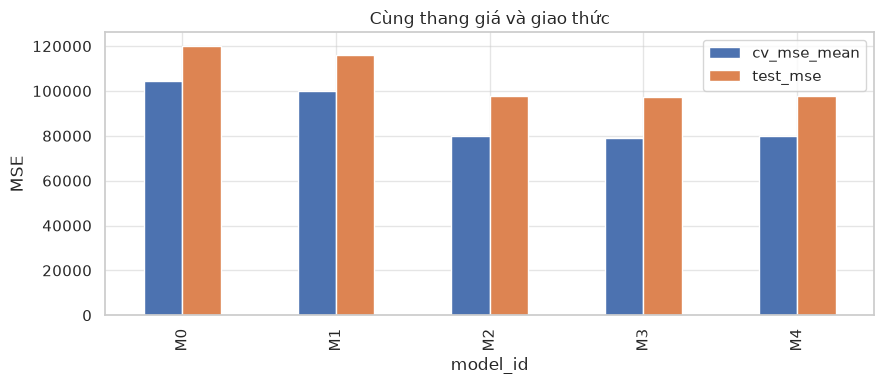

In [18]:
X_test, y_test = test[predictor_names(config)], test[config['target']]
comparison_rows, prediction_frames = [], []
for row in selected_cv.itertuples():
    predicted = models[row.model_id].predict(X_test)
    mse = mean_squared_error(y_test, predicted)
    comparison_rows.append({'model_id': row.model_id, 'variant': row.variant,
        'protocol_id': config['protocol_id'], 'n_train': len(train), 'n_test': len(test),
        'cv_mse_mean': row.cv_mse_mean, 'cv_rmse_mean': row.cv_rmse_mean,
        'cv_mae_mean': row.cv_mae_mean, 'cv_r2_mean': row.cv_r2_mean,
        'test_mse': mse, 'test_rmse': np.sqrt(mse),
        'test_mae': mean_absolute_error(y_test, predicted), 'test_r2': r2_score(y_test, predicted),
        'selected_winning_model': row.model_id == winner_id})
    part = test.copy()
    part['actual'], part['predicted'] = y_test.to_numpy(), predicted
    part['residual'] = part.actual - part.predicted
    part['model_id'], part['split'], part['protocol_id'] = row.model_id, 'test', config['protocol_id']
    prediction_frames.append(part)
comparison = pd.DataFrame(comparison_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
assert len(predictions) == 5 * 10342
assert not predictions.duplicated(['model_id', 'source_file', 'source_row']).any()
display(comparison[['model_id', 'variant', 'cv_mse_mean', 'test_mse', 'test_rmse', 'test_mae',
                    'test_r2', 'selected_winning_model']])
save_table(comparison, 'model_comparison.csv')
save_table(predictions, 'test_predictions.csv')
fig, ax = plt.subplots(figsize=(9, 4))
comparison.set_index('model_id')[['cv_mse_mean', 'test_mse']].plot.bar(ax=ax)
ax.set(title='Cùng thang giá và giao thức', ylabel='MSE')
plt.tight_layout(); plt.show()

## 5. Phần dư, lỗi theo nhóm và kết luận — Huy, Hàn kiểm tra

Residual = actual−predicted: dương nghĩa là dự đoán thấp. Phân tích mô hình đã khóa bằng CV.
Giữ dự đoán âm để phản ánh giới hạn; không clip sau khi nhìn test. Báo lỗi kèm số mẫu từng nhóm.
Các case sai số lớn được truy lại file/dòng, không gọi là gian lận hoặc giá sai.

,grouping,city,n,rmse,mae,mean_residual,negative_predictions,room_type,day_type
0,city,amsterdam,395,265.0974,173.3768,-12.4205,0,NaN,NaN
1,city,athens,1040,580.4380,87.2988,23.3738,70,NaN,NaN
2,city,barcelona,563,306.5031,104.0113,-12.5253,0,NaN,NaN
3,city,berlin,511,292.6332,102.1481,16.0201,2,NaN,NaN
4,city,budapest,780,159.7910,76.1553,-0.7770,28,NaN,NaN
5,city,lisbon,1154,101.2393,71.7593,0.7013,26,NaN,NaN
6,city,london,2020,253.0558,123.7189,-17.9117,0,NaN,NaN
7,city,paris,1323,502.1352,148.6173,11.9242,0,NaN,NaN
8,city,rome,1841,124.2138,78.8640,-0.6450,33,NaN,NaN
9,city,vienna,715,98.3406,71.5729,-10.2406,8,NaN,NaN


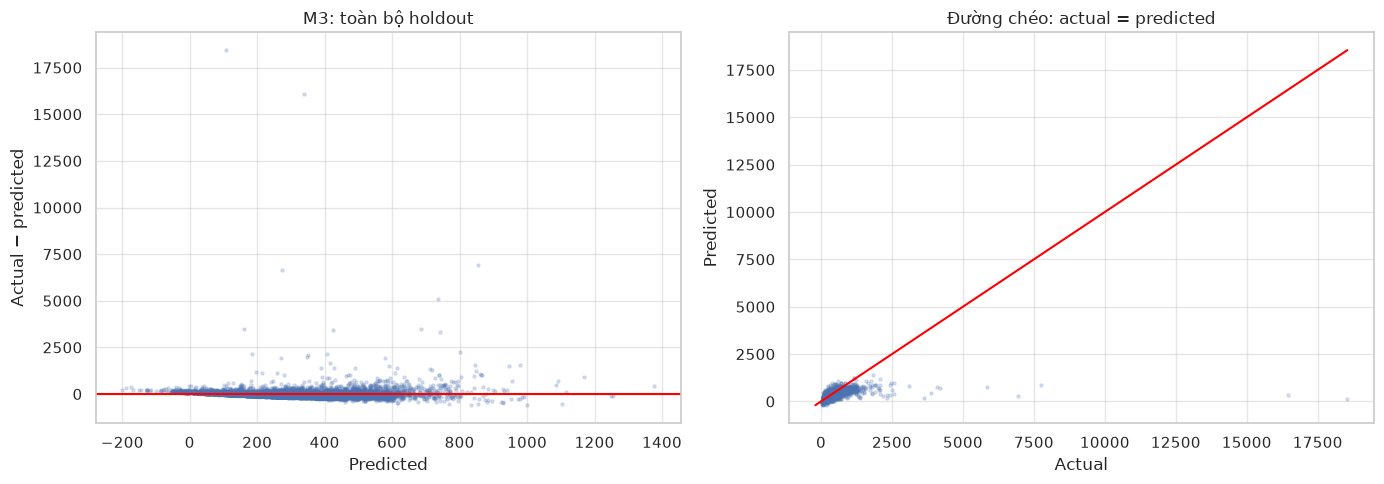

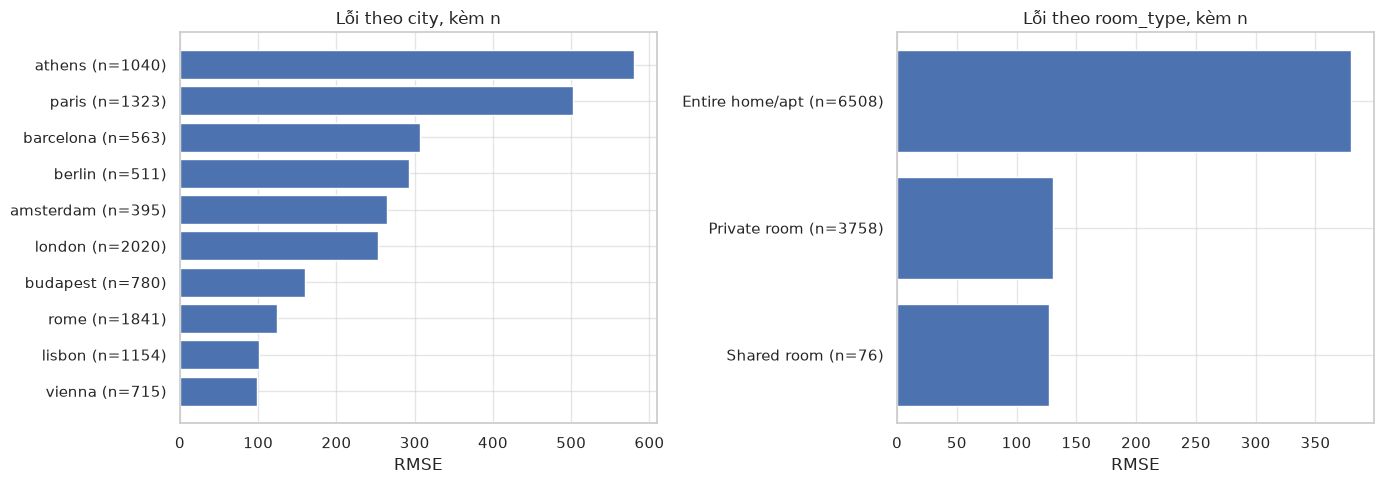

In [19]:
winner = predictions.loc[predictions.model_id.eq(winner_id)].copy()
assert len(winner) == 10342
pd.testing.assert_frame_equal(winner[config['trace_keys']].reset_index(drop=True), test[config['trace_keys']])
np.testing.assert_allclose(winner.actual, test.realSum, rtol=0, atol=0)
winner['abs_residual'] = winner.residual.abs()
winner['squared_residual'] = winner.residual ** 2
def group_error(frame):
    return {'n': len(frame), 'rmse': np.sqrt(frame.squared_residual.mean()),
            'mae': frame.abs_residual.mean(), 'mean_residual': frame.residual.mean(),
            'negative_predictions': int(frame.predicted.lt(0).sum())}
error_rows = []
for cols in [['city'], ['room_type'], ['day_type'], ['city', 'room_type']]:
    for key, part in winner.groupby(cols, observed=True):
        keys = key if isinstance(key, tuple) else (key,)
        error_rows.append({'grouping': '+'.join(cols), **dict(zip(cols, keys)), **group_error(part)})
group_errors = pd.DataFrame(error_rows)
display(group_errors.loc[group_errors.grouping.isin(['city', 'room_type', 'day_type'])])
save_table(group_errors, 'residual_group_errors.csv')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(winner.predicted, winner.residual, s=5, alpha=.2)
axes[0].axhline(0, color='red')
axes[0].set(xlabel='Predicted', ylabel='Actual − predicted', title=f'{winner_id}: toàn bộ holdout')
axes[1].scatter(winner.actual, winner.predicted, s=5, alpha=.2)
low, high = min(winner.actual.min(), winner.predicted.min()), max(winner.actual.max(), winner.predicted.max())
axes[1].plot([low, high], [low, high], color='red')
axes[1].set(xlabel='Actual', ylabel='Predicted', title='Đường chéo: actual = predicted')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ['city', 'room_type']):
    part = group_errors.loc[group_errors.grouping.eq(col)].sort_values('rmse')
    ax.barh([f'{r[col]} (n={int(r["n"])})' for _,r in part.iterrows()], part.rmse)
    ax.set(xlabel='RMSE', title=f'Lỗi theo {col}, kèm n')
plt.tight_layout(); plt.show()

,source_file,source_row,city,room_type,person_capacity,bedrooms,dist,actual,predicted,residual
31719,athens_weekdays.csv,1510,athens,Entire home/apt,2.0000,1,1.1965,"18,545.4503",106.8821,"18,438.5682"
37936,paris_weekdays.csv,2348,paris,Entire home/apt,2.0000,1,4.6024,"16,445.6147",337.5500,"16,108.0647"
37241,london_weekends.csv,4109,london,Entire home/apt,6.0000,3,1.7091,"7,759.3546",853.9734,"6,905.3812"
32689,barcelona_weekdays.csv,1065,barcelona,Entire home/apt,2.0000,1,4.5758,"6,943.7010",273.9734,"6,669.7276"
33501,berlin_weekends.csv,1022,berlin,Entire home/apt,6.0000,3,1.1924,"5,856.0811",736.7028,"5,119.3783"
38800,paris_weekends.csv,3507,paris,Entire home/apt,4.0000,3,3.8694,"4,188.4146",684.8062,"3,503.6084"
33912,budapest_weekdays.csv,1938,budapest,Entire home/apt,3.0000,1,2.0182,"3,630.6810",160.1534,"3,470.5276"
36710,london_weekends.csv,1503,london,Entire home/apt,2.0000,2,7.6790,"3,866.0364",425.9213,"3,440.1151"
37684,paris_weekdays.csv,1041,paris,Entire home/apt,6.0000,3,3.9221,"4,068.6457",741.8529,"3,326.7929"
38145,paris_weekends.csv,256,paris,Entire home/apt,6.0000,3,1.3350,"3,081.8343",802.0882,"2,279.7461"


,Unnamed: 0,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index,attr_index_norm,rest_index,rest_index_norm,lng,lat
1510,1510,"18,545.4503",Entire home/apt,False,False,2.0000,True,0,1,10.0000,100.0000,1,1.1965,0.3811,134.9044,5.0865,275.5737,20.6918,23.7320,37.9860


104 dòng lỗi bình phương lớn nhất (1.01% mẫu) chiếm 86.08% SSE.
Số dự đoán âm: 167
Mean residual: -0.790468059199979 | Median AE: 70.91507643040214 | P90 AE: 186.45871143872773


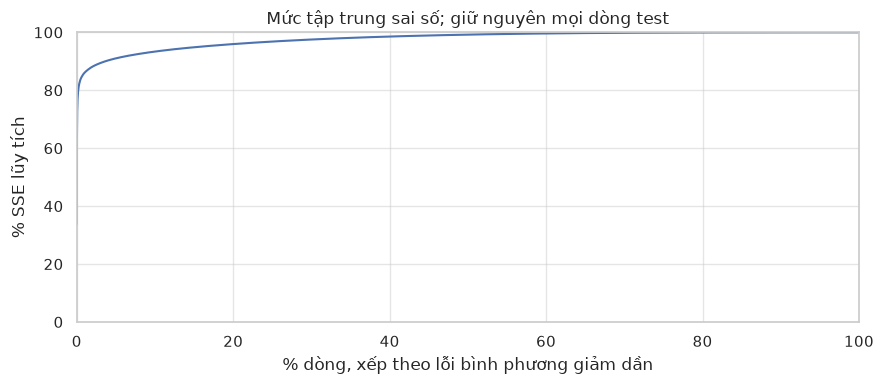

In [20]:
ordered = winner.sort_values('squared_residual', ascending=False)
top_n = int(np.ceil(len(winner)*.01))
top_share = ordered.head(top_n).squared_residual.sum()/winner.squared_residual.sum()
cases = ordered.head(10)[['source_file', 'source_row', 'city', 'room_type', 'person_capacity',
                          'bedrooms', 'dist', 'actual', 'predicted', 'residual']]
display(cases)
save_table(cases, 'residual_cases.csv')
case = cases.iloc[0]
raw_case = pd.read_csv(ROOT / 'data/raw' / case.source_file)
raw_case = raw_case.loc[raw_case['Unnamed: 0'].eq(case.source_row)]
assert len(raw_case) == 1
np.testing.assert_allclose(raw_case.realSum.iloc[0], case.actual, rtol=0, atol=0)
display(raw_case)
print(f'{top_n} dòng lỗi bình phương lớn nhất ({top_n/len(winner):.2%} mẫu) chiếm {top_share:.2%} SSE.')
print('Số dự đoán âm:', winner.predicted.lt(0).sum())
print('Mean residual:', winner.residual.mean(), '| Median AE:', winner.abs_residual.median(),
      '| P90 AE:', winner.abs_residual.quantile(.9))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(ordered)+1)/len(ordered)*100,
        ordered.squared_residual.cumsum()/ordered.squared_residual.sum()*100)
ax.set(xlabel='% dòng, xếp theo lỗi bình phương giảm dần', ylabel='% SSE lũy tích',
       title='Mức tập trung sai số; giữ nguyên mọi dòng test', xlim=(0,100), ylim=(0,100))
plt.tight_layout(); plt.show()

In [21]:
selected = comparison.loc[comparison.model_id.eq(winner_id)].iloc[0]
baseline = comparison.loc[comparison.model_id.eq('M0')].iloc[0]
improvement = (baseline.test_mse-selected.test_mse)/baseline.test_mse*100
display(Markdown(f"""### 5.1. Kết luận từ kết quả thực nghiệm

Phân tích **{len(df):,} quan sát** cho thấy giá lệch phải và mẫu khác cơ cấu giữa các nhóm.
Mean/median/n, Pearson theo city và ANOVA giúp mô tả những liên hệ này, với giới hạn giả định rõ ràng.
**{winner_id}, đa thức bậc 3**, được chọn bằng CV MSE, không chọn theo điểm test.
Trên **{len(test):,} holdout**, RMSE **{selected.test_rmse:.2f}**, MAE **{selected.test_mae:.2f}**,
R² **{selected.test_r2:.4f}**; MSE giảm **{improvement:.2f}%** so với baseline M0 trên cùng test.
Mức giải thích biến thiên còn thấp và có **{int(winner.predicted.lt(0).sum())} dự đoán âm**.
**{top_n} dòng lỗi lớn nhất** chiếm **{top_share:.2%} SSE**, cho thấy ít quan sát có thể chi phối MSE.
Thiếu metadata kỳ giá/listing ID và khả năng lặp tọa độ giữa train/test hạn chế khả năng khái quát.
Kết quả chưa chứng minh nhân quả, gian lận hoặc chất lượng định giá ở một thị trường khác.
"""))

### 5.1. Kết luận từ kết quả thực nghiệm

Phân tích **51,707 quan sát** cho thấy giá lệch phải và mẫu khác cơ cấu giữa các nhóm.
Mean/median/n, Pearson theo city và ANOVA giúp mô tả những liên hệ này, với giới hạn giả định rõ ràng.
**M3, đa thức bậc 3**, được chọn bằng CV MSE, không chọn theo điểm test.
Trên **10,342 holdout**, RMSE **311.70**, MAE **102.02**,
R² **0.1912**; MSE giảm **19.12%** so với baseline M0 trên cùng test.
Mức giải thích biến thiên còn thấp và có **167 dự đoán âm**.
**104 dòng lỗi lớn nhất** chiếm **86.08% SSE**, cho thấy ít quan sát có thể chi phối MSE.
Thiếu metadata kỳ giá/listing ID và khả năng lặp tọa độ giữa train/test hạn chế khả năng khái quát.
Kết quả chưa chứng minh nhân quả, gian lận hoặc chất lượng định giá ở một thị trường khác.


## 6. Phân công, kiểm tra và cách trình bày

### 6.1. Bảng phân công nhiệm vụ chi tiết giữa các thành viên

| Nội dung thực hiện | Thành viên chủ trì | Chi tiết công việc và đóng góp cụ thể |
|---|---|---|
| **1. Dữ liệu và Kiểm toán chất lượng** | **Hàn** | Nạp 20 file CSV, kiểm tra schema, tạo khóa truy vết (`source_file`, `source_row`), xây dựng từ điển dữ liệu, kiểm toán 12 tiêu chí chất lượng, tính IQR phân phối giá và phân nhóm mô tả. |
| **2. Phân tích khám phá (EDA)** | **Huy** | Phân tích cơ cấu số mẫu theo thành phố/loại phòng, so sánh giá giữa ngày thường và cuối tuần, tính tương quan Pearson trên toàn bộ và từng thành phố, thực hiện kiểm định ANOVA một nhân tố. |
| **3. Thiết lập giao thức thực nghiệm** | **Cả hai thành viên** | Thống nhất chia tập 80% Train / 20% Test, cấu hình 5-Fold Cross Validation trên tập Train, lựa chọn allowlist 10 đặc trưng cốt lõi nhằm chống rò rỉ dữ liệu. |
| **4. Mô hình cơ sở (M0, M1, M2)** | **Hàn** | Xây dựng Pipeline cho DummyRegressor (M0), Hồi quy đơn biến (M1), Hồi quy đa biến tuyến tính (M2); trích xuất phương trình hồi quy và phân tích bảng hệ số theo đơn vị gốc. |
| **5. Mô hình nâng cao (M3, M4)** | **Huy** | Xây dựng Pipeline hồi quy đa thức bậc 2 & 3 (M3), hồi quy Ridge với các tham số $\alpha$ khác nhau (M4); đánh giá 5-Fold CV để chọn cấu hình tối ưu. |
| **6. Đánh giá trên tập Holdout Test** | **Cả hai thành viên** | Refit các mô hình tối ưu trên toàn bộ 41.365 mẫu Train, kiểm tra độc lập trên 10.342 mẫu Test bằng 4 chỉ số (MSE, RMSE, MAE, $R^2$), đối chiếu hiệu năng với Baseline M0. |
| **7. Phân tích phần dư & Giới hạn** | **Huy** | Tính toán phần dư, phân tích nồng độ sai số của 1% mẫu có lỗi bình phương lớn nhất, truy vết mẫu gốc và phân tích nguyên nhân các trường hợp dự đoán âm. |
| **8. Báo cáo tổng kết & Slide thuyết trình** | **Cả hai thành viên** | Đọc chéo, đối chiếu 100% số liệu giữa Notebook và Báo cáo nghiệm thu; chuẩn bị slide thuyết trình đồ án và kịch bản vấn đáp. |

---

### 6.2. Hướng dẫn môi trường và tái lập kết quả đồ án (Reproducibility Guide)

- **Môi trường yêu cầu:** Python phiên bản 3.10 trở lên.
- **Các thư viện chính:** `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `seaborn`, `ipython`.
- **Cách thức thực thi:**
  1. Đảm bảo cấu trúc thư mục chứa đầy đủ `data/raw/` (20 tệp CSV) và `config/experiment_config.json`.
  2. Mở tệp notebook `IE313_Airbnb_Final.ipynb` trong môi trường Jupyter Notebook hoặc VS Code.
  3. Chọn lệnh **Kernel -> Restart Kernel and Run All Cells**.
  4. Quá trình tính toán chạy tuần tự từ Cell 0 đến Cell cuối cùng trong khoảng 2–3 phút mà không yêu cầu thêm bất kỳ thao tác thủ công nào.


In [22]:
# Tổng kết và in các chỉ số thực nghiệm chính của toàn bộ đồ án
print("=" * 80)
print("TỔNG KẾT KẾT QUẢ THỰC NGHIỆM ĐỒ ÁN IE313")
print("=" * 80)

print(f"1. Quy mô dữ liệu: {len(df):,} quan sát từ {len(raw_csv_files)} tệp CSV thô.")
print(f"2. Giao thức phân chia: {len(train):,} mẫu Train (80%) | {len(test):,} mẫu Test (20%).")
print(f"3. Đánh giá 5-Fold Cross Validation trên tập Train: hoàn tất 12 cấu hình mô hình.")
print(f"4. Mô hình được chọn qua 5-Fold CV: {winner_id} (Đa thức bậc 3).")
print(f"   -> Điểm CV MSE trung bình: {selected_cv.loc[selected_cv.model_id.eq(winner_id), 'cv_mse_mean'].iloc[0]:,.2f}")

print("\n5. Hiệu năng kiểm tra độc lập trên tập Holdout Test (10.342 mẫu):")
print(f"   - MSE  : {selected.test_mse:,.2f} (Cải thiện {improvement:.2f}% so với Baseline M0)")
print(f"   - RMSE : {selected.test_rmse:,.2f} EUR")
print(f"   - MAE  : {selected.test_mae:,.2f} EUR")
print(f"   - R²   : {selected.test_r2:.4f}")

print(f"\n6. Phân tích phần dư & giới hạn mô hình:")
print(f"   - Số trường hợp dự đoán âm: {int(winner.predicted.lt(0).sum())} mẫu (chiếm {winner.predicted.lt(0).sum()/len(winner):.2%})")
print(f"   - Nồng độ sai số: {top_n} mẫu sai số lớn nhất (1% mẫu) chiếm {top_share:.2%} tổng bình phương phần dư (SSE).")
print("=" * 80)
print("-> ĐÃ HOÀN TẤT THỰC THI TOÀN BỘ NOTEBOOK THÀNH CÔNG VÀ NHẤT QUÁN.")


TỔNG KẾT KẾT QUẢ THỰC NGHIỆM ĐỒ ÁN IE313
1. Quy mô dữ liệu: 51,707 quan sát từ 20 tệp CSV thô.
2. Giao thức phân chia: 41,365 mẫu Train (80%) | 10,342 mẫu Test (20%).
3. Đánh giá 5-Fold Cross Validation trên tập Train: hoàn tất 12 cấu hình mô hình.
4. Mô hình được chọn qua 5-Fold CV: M3 (Đa thức bậc 3).
   -> Điểm CV MSE trung bình: 79,228.00

5. Hiệu năng kiểm tra độc lập trên tập Holdout Test (10.342 mẫu):
   - MSE  : 97,156.55 (Cải thiện 19.12% so với Baseline M0)
   - RMSE : 311.70 EUR
   - MAE  : 102.02 EUR
   - R²   : 0.1912

6. Phân tích phần dư & giới hạn mô hình:
   - Số trường hợp dự đoán âm: 167 mẫu (chiếm 1.61%)
   - Nồng độ sai số: 104 mẫu sai số lớn nhất (1% mẫu) chiếm 86.08% tổng bình phương phần dư (SSE).
-> ĐÃ HOÀN TẤT THỰC THI TOÀN BỘ NOTEBOOK THÀNH CÔNG VÀ NHẤT QUÁN.
